In [1]:
#sayad alakbarov
#mini-project-2

In [ ]:
# Question 1
# Before looking at the data, we can use some intuition about what might make a firm more or less likely to evade taxes.
# Firm size / Money Value:
# Bigger or more profitable firms may have more to lose if caught,but they might also have more resources to hide income.
# So the effect could go either way.
# Industry / Sector: 
# Some sectors are more cash-based (like construction or retail),which makes evasion easier and harder to detect.
# Discrepancy variables (PARA A, PARA B):Large gaps between reported and actual values could indicate manipulation.
# Previous risk scores (Risk A, Risk B, Risk D):
# Firms that were risky before are likely to stay risky — past behavior predicts future behavior.
# Audit risk:
# A higher chance of being audited should discourage evasion because the expected penalty is higher.
# Overall:
# I expect positive coefficients for discrepancy and past-risk variables, and negative coefficients for audit-related variables.

In [3]:
# Question 2
# If the true model includes an important interaction between two variables but we do not explicitly include that interaction term in the Linear Probability Model (LPM),
# the LPM cannot capture the combined nonlinear effect of those predictors.
# K-Nearest Neighbors (KNN), on the other hand, does not assume a specific linear form. It makes predictions based on the similarity of observations in the feature space.
# This means that if the interaction between variables affects the outcome, KNN can still reflect that relationship because nearby points will naturally
# share similar joint values of the two predictors.
# In short:
# KNN can implicitly capture nonlinear and interaction effects, while the LPM can only represent them if we explicitly add interaction terms.

In [5]:
# Question 3-a

import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import confusion_matrix

df = pd.read_csv("/Users/sayad.alakbarov/Desktop/Data-Audit.csv")      
df = df.dropna()                    

y = df["Risk"]                          
X = df.drop(columns=["Risk"])         

X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.5, random_state=13
)

lpm = LinearRegression()
lpm.fit(X_train, y_train)

y_pred_prob = lpm.predict(X_val)

y_pred_class = (y_pred_prob > 0.5).astype(int)

cm = confusion_matrix(y_val, y_pred_class)
print("Confusion Matrix (rows = true, columns = predicted):")
print(cm)

Confusion Matrix (rows = true, columns = predicted):
[[221   8]
 [ 29 130]]


In [ ]:
#(B)
y_pred_class_06 = (y_pred_prob > 0.6).astype(int)
cm_06 = confusion_matrix(y_val, y_pred_class_06)
print("Confusion Matrix (rows = true, columns = predicted):")
print(cm_06)

Confusion Matrix (rows = true, columns = predicted):
[[225   4]
 [ 39 120]]


In [9]:
#(c)
err_05 = (cm[0,1] + cm[1,0]) / cm.sum()

err_06 = (cm_06[0,1] + cm_06[1,0]) / cm_06.sum()

print(f"Error rate (threshold = 0.5): {err_05:.4f}")
print(f"Error rate (threshold = 0.6): {err_06:.4f}")

if err_05 < err_06:
    print("→ The 0.5 threshold produces more accurate overall predictions.")
elif err_06 < err_05:
    print("→ The 0.6 threshold produces more accurate overall predictions.")
else:
    print("→ Both thresholds give the same overall accuracy.")

Error rate (threshold = 0.5): 0.0954
Error rate (threshold = 0.6): 0.1108
→ The 0.5 threshold produces more accurate overall predictions.


In [10]:
#(c)-interpretation
# Error rate (threshold = 0.5): 0.0954
# Error rate (threshold = 0.6): 0.1108
# The 0.5 threshold produces more accurate overall predictions.

In [12]:
#(d)
tp_05 = cm[1,1]
fp_05 = cm[0,1]
precision_05 = tp_05 / (tp_05 + fp_05)


tp_06 = cm_06[1,1]
fp_06 = cm_06[0,1]
precision_06 = tp_06 / (tp_06 + fp_06)

print(f"Precision (threshold = 0.5): {precision_05:.4f}")
print(f"Precision (threshold = 0.6): {precision_06:.4f}")

Precision (threshold = 0.5): 0.9420
Precision (threshold = 0.6): 0.9677


In [13]:
#(d)-interpretation
# Precision (threshold = 0.5): 0.9420
# Precision (threshold = 0.6): 0.9677
# When using the higher cutoff (0.6), the model becomes more conservative
# about labeling firms as evaders — but those it does label are more likely
# to have truly evaded taxes.
# Therefore, the 0.6 threshold yields higher precision (96.8%) than 0.5 (94.2%)

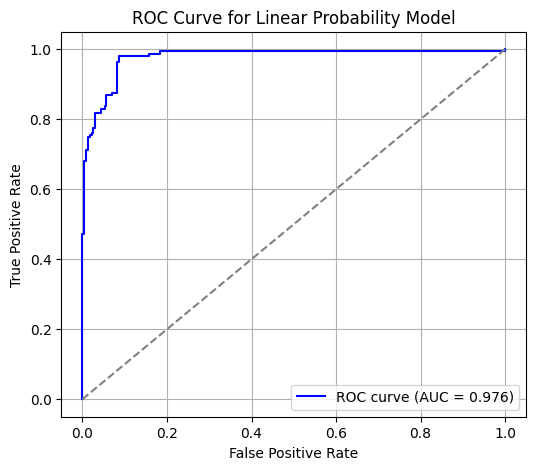

AUC Score: 0.976


In [ ]:
#(e)

import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score

fpr, tpr, thresholds = roc_curve(y_val, y_pred_prob)

auc_score = roc_auc_score(y_val, y_pred_prob)

plt.figure(figsize=(6,5))
plt.plot(fpr, tpr, color='blue', label=f'ROC curve (AUC = {auc_score:.3f})')
plt.plot([0,1], [0,1], color='gray', linestyle='--')
plt.title('ROC Curve for Linear Probability Model')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend()
plt.grid(True)
plt.show()

print(f"AUC Score: {auc_score:.3f}")

In [17]:
#(e)-interpretation
# AUC Score: 0.976
# Interpretation:
# The ROC curve plots the trade-off between the True Positive Rate (sensitivity) and the False Positive Rate across all possible classification thresholds.
# A higher curve (closer to the top-left corner) indicates better performance.
#
# The AUC (Area Under the Curve) summarizes this performance into a single number.
#  An AUC of 0.976 means the model has excellent discriminatory power, it can correctly distinguish between firms that evaded taxes and those that did not about 97.6% of the time.
#
# The ROC curve extends the comparison in earlier parts by showing how model accuracy changes at *all* thresholds, not just at 0.5 or 0.6.
# In other words, instead of evaluating the model at one cutoff, it shows performance over the entire range of possible thresholds.

In [ ]:
# UQuestion 4

# In this setting, a false negative (a firm that actually evaded taxes but was predicted as honest) is more costly than a false positive (a firm predicted to have evaded but actually did not).
#
# A false negative means the government fails to detect and penalize a cheating firm, leading to lost tax revenue and a weaker deterrent effect.
# A false positive, while inconvenient for the firm, only wastes some audit resources.
#Therefore, policymakers would usually prefer to reduce false negatives, even at the cost of having more false positives.
#
# Changing the classification threshold affects this trade-off:
# Lowering the threshold (e.g., from 0.6 to 0.5) increases sensitivity, more firms are flagged as potential evaders, reducing false negatives but increasing false positives.
# Raising the threshold makes the model more conservative, decreasing false positives but increasing false negatives.
#
# The optimal threshold depends on which type of error is considered more costly for the government’s objectives and budget.

In [20]:
# Question 5

from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, y_train)
y_pred_prob_knn = knn.predict_proba(X_val)[:, 1]
y_pred_class_knn = (y_pred_prob_knn > 0.5).astype(int)

# (a) 
cm_knn = confusion_matrix(y_val, y_pred_class_knn)
print("Confusion Matrix (rows = true, columns = predicted):")
print(cm_knn)

# (b)
error_rate_knn = (cm_knn[0,1] + cm_knn[1,0]) / cm_knn.sum()
print(f"\nError rate: {error_rate_knn:.4f}")
print(f"Overall accuracy: {1 - error_rate_knn:.4f}")

# (c)
tp_knn = cm_knn[1,1]
fp_knn = cm_knn[0,1]
precision_knn = tp_knn / (tp_knn + fp_knn)
print(f"Precision (predicted evaders who actually evaded): {precision_knn:.4f}")

Confusion Matrix (rows = true, columns = predicted):
[[226   3]
 [ 11 148]]

Error rate: 0.0361
Overall accuracy: 0.9639
Precision (predicted evaders who actually evaded): 0.9801


In [21]:
# Question 5- Interpretation
# (a) Confusion Matrix:
# [[226   3]
#  [ 11 148]]
# (b) Error rate and accuracy:
# Error rate = 0.0361
# Overall accuracy = 0.9639
# (c) Proportion of predicted evaders who actually evaded (Precision):
# Precision = 0.9801
# Interpretation:
# The KNN model with k = 5 performs very well, correctly classifying about 96% of firms.It produces only 3 false positives and 11 false negatives.
# The high precision (98%) means that nearly all firms predicted as evaders actually did evade taxes.
# Compared to the Linear Probability Model, KNN achieves higher accuracy and better precision, suggesting it captures nonlinear patterns more effectively.

In [23]:
# Question 6
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

knn_scaled = Pipeline([
    ("scaler", StandardScaler()),
    ("knn", KNeighborsClassifier(n_neighbors=5))
])

knn_scaled.fit(X_train, y_train)

y_pred_prob_knn_scaled = knn_scaled.predict_proba(X_val)[:, 1]
y_pred_class_knn_scaled = (y_pred_prob_knn_scaled > 0.5).astype(int)

# (a)
cm_knn_scaled = confusion_matrix(y_val, y_pred_class_knn_scaled)
print("Confusion Matrix (rows = true, columns = predicted):")
print(cm_knn_scaled)

# (b) 
error_rate_knn_scaled = (cm_knn_scaled[0,1] + cm_knn_scaled[1,0]) / cm_knn_scaled.sum()
accuracy_knn_scaled = 1 - error_rate_knn_scaled
print(f"\nError rate: {error_rate_knn_scaled:.4f}")
print(f"Overall accuracy: {accuracy_knn_scaled:.4f}")

# (c)
tp_scaled = cm_knn_scaled[1,1]
fp_scaled = cm_knn_scaled[0,1]
precision_scaled = tp_scaled / (tp_scaled + fp_scaled)
print(f"Precision (predicted evaders who actually evaded): {precision_scaled:.4f}")

Confusion Matrix (rows = true, columns = predicted):
[[221   8]
 [ 12 147]]

Error rate: 0.0515
Overall accuracy: 0.9485
Precision (predicted evaders who actually evaded): 0.9484


In [24]:
# Question 6- interpretation
# (a) Confusion Matrix:
# [[221   8]
#  [ 12 147]]
# (b) Error rate and accuracy:
# Error rate = 0.0515
# Overall accuracy = 0.9485
# (c) Proportion of predicted evaders who actually evaded (Precision):
# Precision = 0.9484
# Interpretation:
#After scaling the predictors, the KNN model remains highly accurate but performs slightly worse than the unscaled version (accuracy fell from 0.9639 to 0.9485).
# The precision also dropped slightly, from about 98% to 95%.
#This small difference suggests that the original predictors were already on comparable scales or that scaling slightly altered the neighborhood structure.
#In general, scaling is important for KNN because it ensures that all variables contribute equally to distance calculations.

In [26]:
# Question 7
# The unscaled KNN model performed slightly better:
# Unscaled KNN accuracy = 0.9639, precision = 0.9801
# Scaled KNN accuracy  = 0.9485, precision = 0.9484
# Therefore, the KNN model without normalization gave more accurate and precise predictions.
#
# I make this determination by directly comparing the error rates and accuracyfrom both models on the same validation set.

# In theory, scaling should usually improve KNN performance because it prevents variables with larger numeric ranges from dominating the distance calculations.
# However, in this dataset, the predictors may have been on similar scales already,or scaling may have slightly distorted meaningful differences among variables.

# As a result, normalization did not improve the model in this specific case, and the unscaled version performed marginally better.

In [28]:
# Question 8
from sklearn.model_selection import cross_val_score, KFold

X_full = df.drop(columns=["Risk"])
y_full = df["Risk"]

cv = KFold(n_splits=5, shuffle=True, random_state=13)

k_values = range(1, 21)
cv_errors = []

for k in k_values:
    knn_cv = KNeighborsClassifier(n_neighbors=k)
    scores = cross_val_score(knn_cv, X_full, y_full, cv=cv, scoring='accuracy')
    cv_errors.append(1 - scores.mean())

best_k = k_values[np.argmin(cv_errors)]
best_error = min(cv_errors)

print("k values tested:", list(k_values))
print("CV error rates:", [round(e, 4) for e in cv_errors])
print(f"\nBest k = {best_k} with lowest CV error rate = {best_error:.4f}")

k values tested: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20]
CV error rates: [np.float64(0.0206), np.float64(0.0335), np.float64(0.0335), np.float64(0.0361), np.float64(0.0348), np.float64(0.0361), np.float64(0.0348), np.float64(0.04), np.float64(0.0374), np.float64(0.0387), np.float64(0.0387), np.float64(0.0439), np.float64(0.0387), np.float64(0.0465), np.float64(0.0413), np.float64(0.0503), np.float64(0.049), np.float64(0.0516), np.float64(0.049), np.float64(0.0555)]

Best k = 1 with lowest CV error rate = 0.0206


In [29]:
# Q8- interpretation
# k values tested: 1–20
# CV error rates: [0.0206, 0.0335, 0.0335, 0.0361, 0.0348, 0.0361, 0.0348, 0.0400, 0.0374, 0.0387, ...]
# Best k = 1 with the lowest CV error rate = 0.0206
#
# Interpretation:
# The 5-fold cross-validation shows that k = 1 yields the most accurate predictions (lowest classification error) when using the full dataset without normalization.
# This means the model that uses each firm’s single nearest neighbor performs best at reproducing the observed outcomes.
# However, a very small k (like 1) can make the model more sensitive to noise it fits the training data very closely, which might slightly reduce generalization.
# In practice, while k = 1 gives the lowest CV error here, slightly higher values (like k = 3 or k = 5) might be preferred  to achieve a smoother and more stable model across different samples.

In [30]:
# Question 9

# The key issue is **sample selection bias**. The data used to train the KNN model only includes firms that were already audited.
# These firms are not a random sample of all firms in the population, they were likely chosen for audit based on prior risk indicators.
# As a result, the model learns patterns specific to firms that were audited, not to all firms in the economy.
# If the government uses this model to target future audits, it may keep focusing on similar types of firms and ignore others, reinforcing the original bias in audit selection.
# In the long run, this feedback loop could make the system less fair and less effective because new or different kinds of tax evasion may go undetected.
# To avoid this, the government would need to retrain or adjust the model using data from a broader and more representative sample of firms,including some that were not previously audited.